In [1]:
import sys

from pathlib import Path
project_root = Path.cwd().parent    # notebooks -> project_root
sys.path.insert(0, str(project_root))
print(project_root)

from matplotlib import pyplot as plt
import numpy as np

from FenicsxModels.PoissonSolvers import PoissonCG
from FenicsxModels.FenicsxPriors import PriorSPDE

/Users/tcui0786/Work/DeepTransport/PyFInS


In [ ]:
# import os
# import shutil

# os.environ["CC"] = "/usr/bin/clang"
# os.environ["CXX"] = "/usr/bin/clang++"
# os.environ.pop("LD", None)

# print("env CC      =", os.environ.get("CC"))
# print("env CXX     =", os.environ.get("CXX"))
# print("env LD      =", os.environ.get("LD"))
# print("SDKROOT     =", os.environ.get("SDKROOT"))
# print("CONDA_BUILD_SYSROOT =", os.environ.get("CONDA_BUILD_SYSROOT"))


env CC      = /usr/bin/clang
env CXX     = /usr/bin/clang++
env LD      = None
SDKROOT     = /Library/Developer/CommandLineTools/SDKs/MacOSX.sdk
CONDA_BUILD_SYSROOT = None
clang = /Users/tcui0786/conda/bin/clang
prefixed clang = /Users/tcui0786/conda/bin/arm64-apple-darwin20.0.0-clang


In [2]:
# mesh size
Nx = 24
Ny = 24
corner_points=((0.0, 0.0), (2.0, 2.0))

# Dirichlet data
def gL(y): return 1.0 + 0.5*y
def gR(y): return - np.sin(2.0*np.pi*y) - 1.0

# observation grid
obs_n_grid = 4
obs_eps = 2.0/Nx

model = PoissonCG(corner_points, Nx, Ny, gL, gR, order=1, const_k=True, log_normal=True)
model.make_observation_operator(obs_n_grid, obs_eps)
prior = PriorSPDE(model.Kh, sigma = 1, ell = 1.0, mu = 0.0)


/var/folders/35/sjd32gz17sdgbnzs84sr2kb80000gp/T/ipykernel_3092/382424724.py:14: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


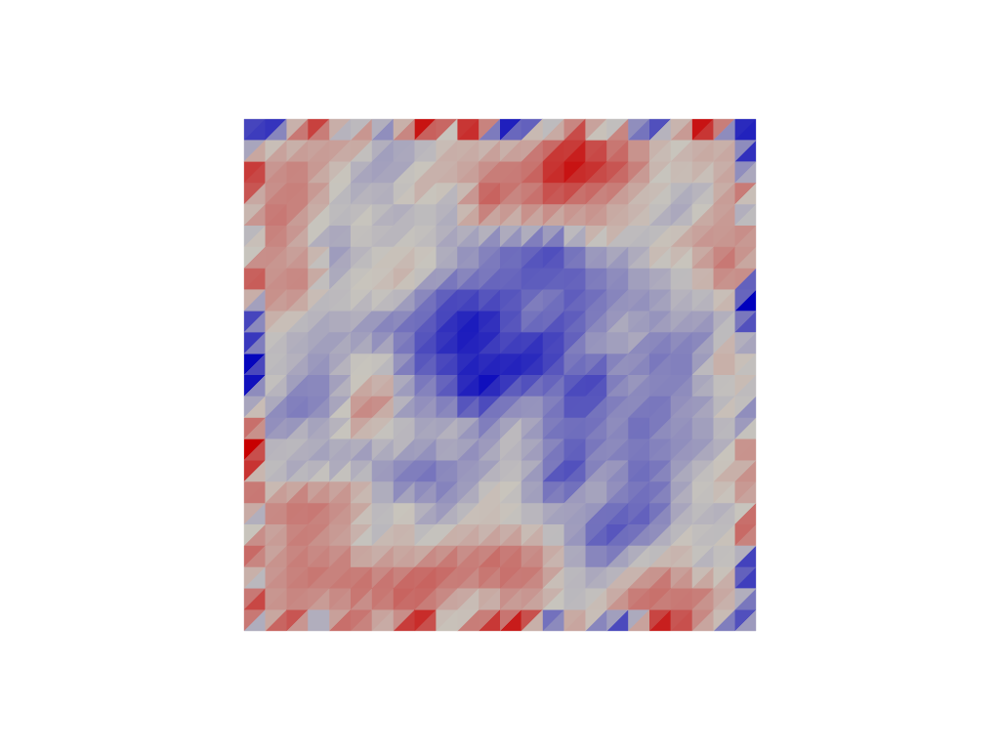

In [3]:
from dolfinx import fem
import math 
import pyvista
from FenicsxModels import Helpers

x_true = prior.sample()

plotter = pyvista.Plotter()
phi = fem.Function(prior.Kh)
phi.x.array[:] = x_true
plot_grid = Helpers.plotting_grid(phi)
plotter.add_mesh(plot_grid, show_edges=False, show_scalar_bar=False, cmap="bwr")
plotter.view_xy()
plotter.show()

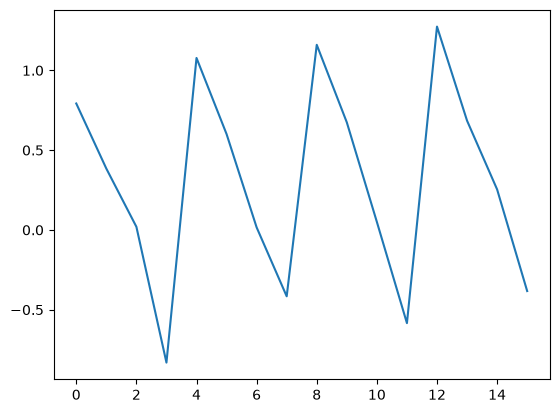

In [4]:
from BaseModels import GaussianLikelihood

y, _ = model.solve(x_true)

sig2noise = 10
sigma = np.abs(y).mean()/sig2noise
fake_data = y + np.random.normal(0, sigma, size=y.shape)
like = GaussianLikelihood(fake_data, sigma)

plt.plot(fake_data)
plt.show()

In [ ]:
from FenicsxInference import LikelihoodInformedSMC, LikelihoodInformedSubspace
from InferenceTools.TransitionKernels import OneStepKernel

kernel = OneStepKernel(
        type="OW",
        sigma=-3.0,
        adapt=True,
        nbatch=1,
)

LIS = LikelihoodInformedSubspace(prior=prior, epsilon=0.1)

sampler = LikelihoodInformedSMC(
        prior,
        model,
        like,
        LIS,
        kernel,
        max_iter=100,
        n_samples=1000,
        n_mutation_steps=20,
        n_final_mutation_steps=100,
        ess_tol=0.5,
        min_beta=1e-6,
        pm_sample_size=5,
)

sampler.iterate()

model: 100%|██████████| 20000/20000 [05:21<00:00, 62.26it/s]

[0.0111926  0.03173607 0.03277146 0.01695818 0.01398615 0.03596684
 0.03585192 0.01418897 0.01567303 0.03947105 0.03936895 0.01883714
 0.01616226 0.0376592  0.0373331  0.01537364]



data-free LIS: 100%|██████████| 2000/2000 [01:49<00:00, 18.27it/s]


Data-free LIS dimension 11
No GPU available. Training will run on CPU.
AttentionSplineFlow model parameters: 4881


100%|██████████| 1/1 [00:00<00:00, 20.16it/s]


Test loss: 5.606
Validation loss: 5.782 (95% CI: [nan, nan])
Test loss: 5.606 (95% CI: [nan, nan])
No GPU available. Training will run on CPU.
AttentionSplineFlow model parameters: 5073


100%|██████████| 1/1 [00:00<00:00,  6.92it/s]


Test loss: 15.636
Validation loss: 15.834 (95% CI: [nan, nan])
Test loss: 15.636 (95% CI: [nan, nan])


model: 100%|██████████| 20000/20000 [08:14<00:00, 40.44it/s]


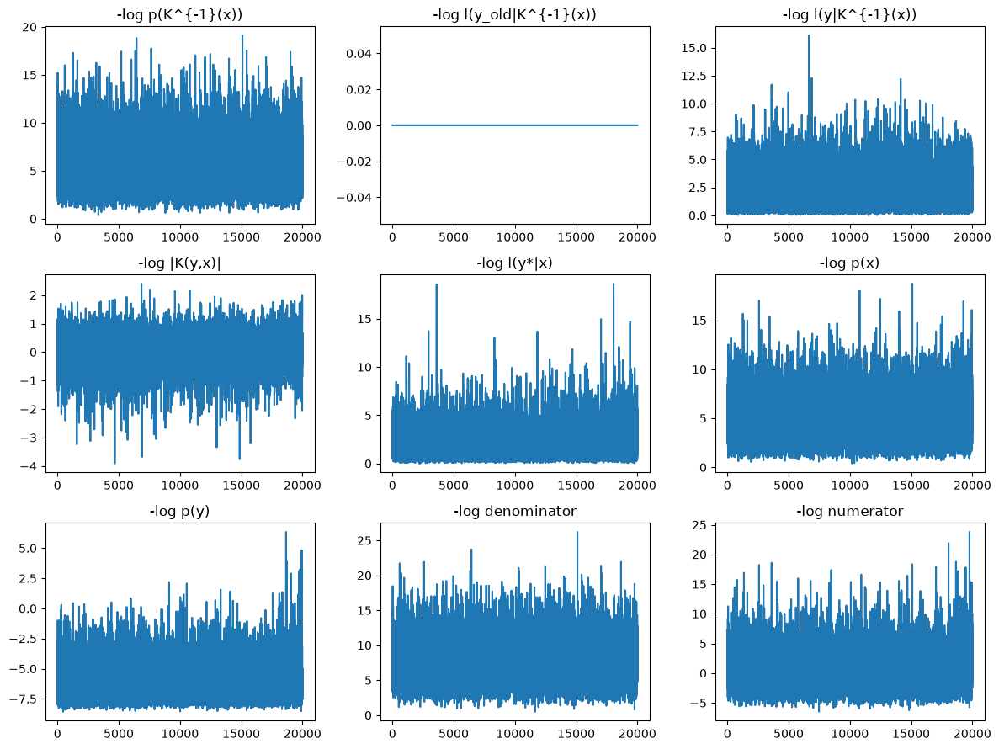

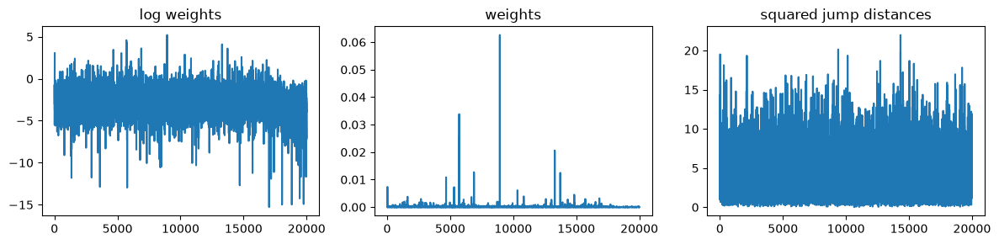

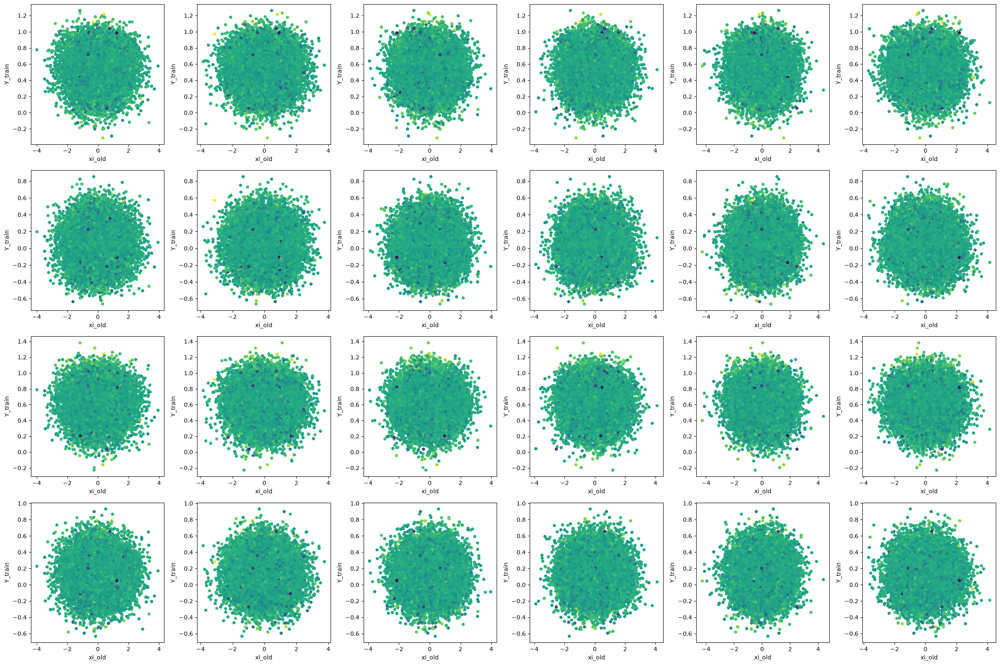

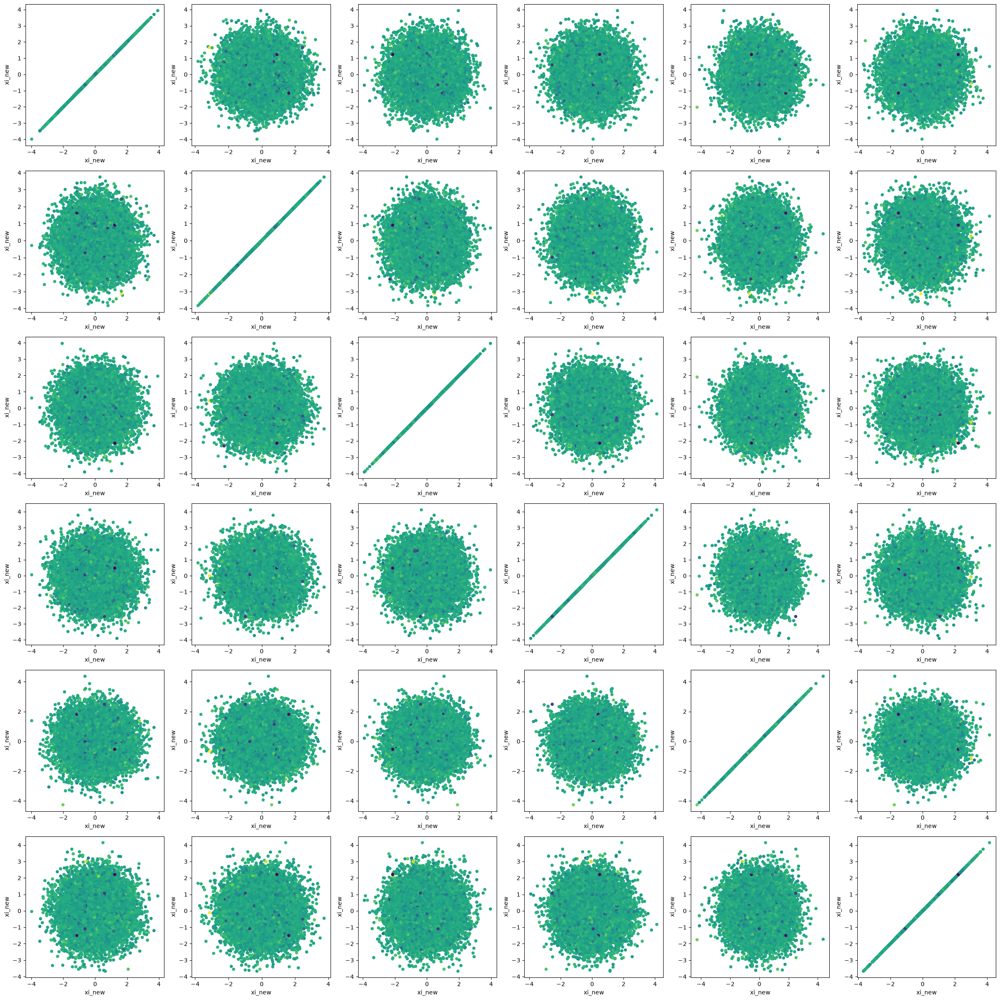

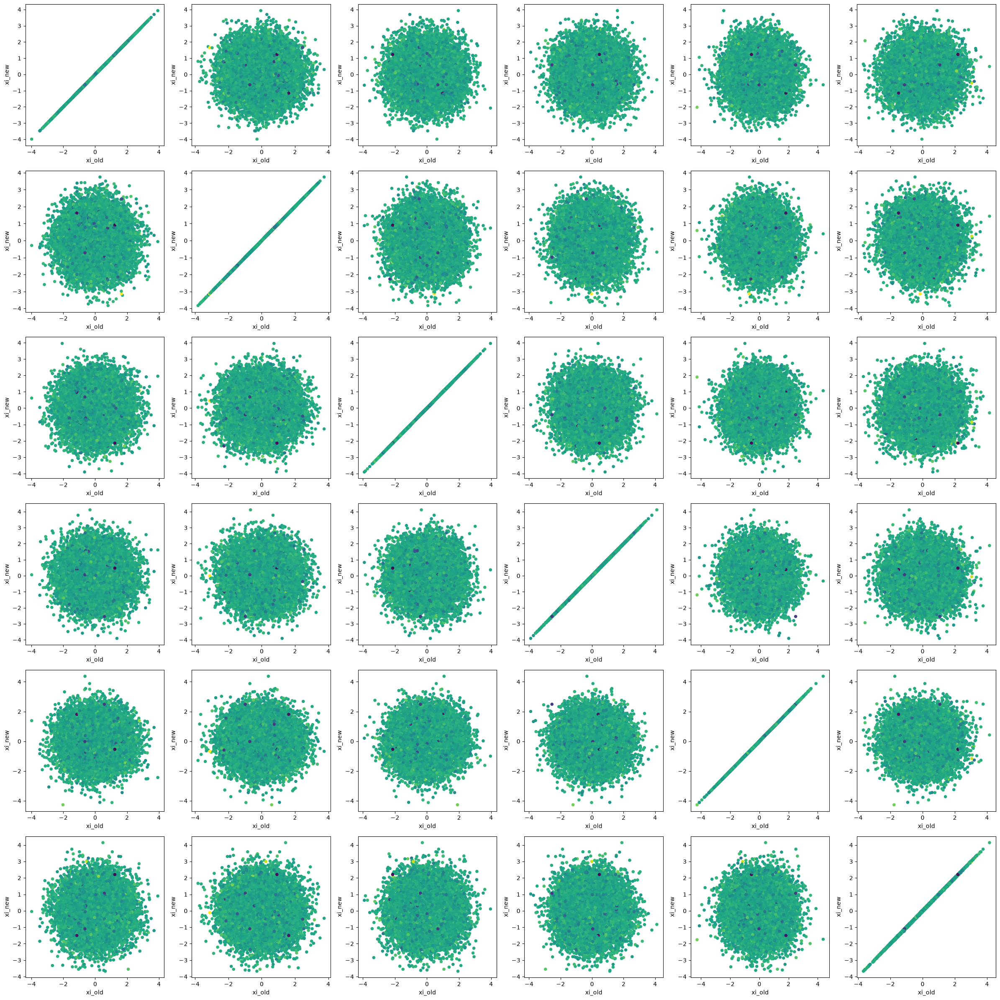

weights: min=7.876e-11, mean=5.000e-05, max=6.261e-02
The ESS per sample is 0.007089195284028804


In [6]:
from FenicsxInference import LikelihoodInformedIterativeInference, LikelihoodInformedSubspace

LIS = LikelihoodInformedSubspace(prior=prior, epsilon=0.1)

itermap = LikelihoodInformedIterativeInference(
        prior,
        model,
        like,
        LIS_template=LIS,
        map_order=2,
        n_samples=20000,
        re_weight=False,
)
# iter 0
itermap.iterate_with_design(n_design=4, plot_iter=True)

In [ ]:

# iter 1
itermap.iterate_with_design(n_design=4, plot_iter=True)